# Capítulo 3 · Actividad: análisis de datos con NumPy, pandas y matplotlib

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/riosinda/ml-course/blob/main/notebooks/exercises/chapter_03/01_actividad_numpy_pandas.ipynb)

En esta actividad haces de **analista de datos**: vas a responder preguntas sobre datos reales con **NumPy** y **pandas**, y después los visualizarás con **matplotlib** y **seaborn**. Lo importante no es solo que el código funcione, sino que **sepas interpretar los resultados**.

### Antes de empezar

1. **Copia esta notebook a `workspace/`** y trabaja sobre la copia. Si editas el original tendrás conflictos al sincronizar tu fork.
2. Si todavía no tienes los datos, descárgalos desde la raíz del repo:
   ```bash
   uv run python scripts/download_data.py
   ```
3. Ten a mano las notebooks de clase de `notebooks/lectures/chapter_03/`: `01_numpy`, `02_pandas` y `03_matplotlib`.

### Cómo trabajar

- Cada ejercicio tiene una celda `# Tu código aquí`. Puedes añadir todas las celdas que necesites.
- En las celdas ✍️ responde con tus palabras y **apoya tus respuestas con números** de tus resultados.
- En las partes 1 y 2, las 💡 **pistas** te recuerdan funciones. Si una función no salió en clase, la pista explica cómo usarla. La parte 3 no tiene pistas.
- Al terminar, ejecuta **Kernel → Restart & Run All** y comprueba que todo funciona de arriba abajo.

| Parte | Datos | Herramienta |
|---|---|---|
| 1. La cafetería | ventas de un mes (generadas en la notebook) | NumPy |
| 2. Las propinas | `data/tips.csv` | pandas (+ un poco de NumPy) |
| 3. Visualización | cafetería, propinas y `data/penguins.csv` | matplotlib y seaborn |

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Carpeta data/ en la raíz del repo: subimos de carpeta en carpeta hasta dar con pyproject.toml
raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), Path.cwd())
DATA_DIR = raiz / "data"
print("Carpeta de datos:", DATA_DIR)

Carpeta de datos: c:\Users\nouneim\InstRoot\Prgms\MnPrjcts\ml-course\data


---
## Parte 1 · La cafetería ☕ (NumPy)

Una cafetería vende 5 productos y ha registrado cuántas unidades vendió de cada uno durante **4 semanas** (28 días, de lunes a domingo). La dueña quiere saber cuánto gana, qué días van mejor y qué producto le conviene más.

Ejecuta la siguiente celda para generar los datos. **No hace falta que la modifiques ni que entiendas cada línea.**

In [2]:
# Datos de la cafetería (no hace falta modificar esta celda)
rng = np.random.default_rng(42)

productos = np.array(["café", "latte", "té", "croissant", "sándwich"])
precios = np.array([1.5, 2.8, 1.2, 2.0, 4.5])       # precio de cada producto, en $

# Unidades vendidas cada día: los fines de semana se vende un 50% más
dia_semana = np.tile(np.arange(7), 4)                # 0 = lunes, ..., 6 = domingo
factor = np.where(dia_semana >= 5, 1.5, 1.0)
promedio = np.outer(factor, [30, 22, 12, 18, 9])     # ventas esperadas por día y producto
ventas_planas = rng.poisson(promedio).ravel()         # ¡todo en una sola fila!

print(ventas_planas[:10], "...")
print("Número de valores:", ventas_planas.size)

[35 28  7 16 13 29 16 10 18 11] ...
Número de valores: 140


### Ejercicio 1 · Dar forma a los datos

`ventas_planas` tiene 140 números seguidos: primero las ventas de los 5 productos del día 1, después las del día 2, y así sucesivamente.

a) Crea una matriz `ventas` con forma `(28, 5)`: una **fila por día** y una **columna por producto** (en el mismo orden que `productos`).

b) Imprime su `shape`, `ndim`, `size` y `dtype`.

c) ¿Cuántos cafés se vendieron el primer día? Comprueba que coincide con `ventas_planas[0]`.

> 💡 **Pista:** `reshape`.

In [3]:
# a) una fila por día, una columna por producto
ventas = ventas_planas.reshape(28, 5)

# b) atributos de la matriz
print("shape:", ventas.shape)
print("ndim: ", ventas.ndim)
print("size: ", ventas.size)
print("dtype:", ventas.dtype)

# c) cafés vendidos el primer día (fila 0, columna 0)
print("Cafés el primer día:", ventas[0, 0])
print("Coincide con ventas_planas[0]:", ventas[0, 0] == ventas_planas[0])

shape: (28, 5)
ndim:  2
size:  140
dtype: int64
Cafés el primer día: 35
Coincide con ventas_planas[0]: True


### Ejercicio 2 · Indexación

Obtén, usando índices y *slicing* sobre `ventas`:

a) Las ventas de todos los productos el **primer día**.

b) Las ventas de **latte** (columna 1) durante todo el mes.

c) Las ventas de la **última semana** (los últimos 7 días). Comprueba que su forma es `(7, 5)`.

d) Las ventas de **croissant y sándwich** (las dos últimas columnas) durante la **primera semana**.

> 💡 **Pista:** `M[filas, columnas]`. Recuerda que los índices negativos cuentan desde el final.

In [4]:
# a) todas las columnas de la primera fila
print("a) Primer día:", ventas[0])

# b) toda la columna 1 (latte)
print("b) Latte en el mes:", ventas[:, 1])

# c) últimas 7 filas
ultima_semana = ventas[-7:]
print("c) Forma de la última semana:", ultima_semana.shape)

# d) primeras 7 filas, dos últimas columnas
print("d) Croissant y sándwich, semana 1:\n", ventas[:7, -2:])

a) Primer día: [35 28  7 16 13]
b) Latte en el mes: [28 16 17 21 17 29 37 16 23 25 22 19 29 39 24 19 18 22 30 44 27 14 31 21
 30 26 32 45]
c) Forma de la última semana: (7, 5)
d) Croissant y sándwich, semana 1:
 [[16 13]
 [18 11]
 [17 10]
 [15  8]
 [17  8]
 [22 14]
 [29 12]]


### Ejercicio 3 · Ingresos

a) Calcula la matriz `ingresos` (forma `(28, 5)`): lo que se ingresó por cada producto cada día.

b) ¿Cuánto ingresó la cafetería en todo el mes?

c) Crea `ingreso_diario`, un array con el ingreso total de **cada día** (forma `(28,)`).

d) ¿Cuál fue el ingreso diario medio, el máximo y el mínimo?

> 💡 **Pistas:**
> - `ventas * precios` multiplica **cada fila** de `ventas` por el vector `precios`, elemento a elemento: la columna del café por 1.5, la del latte por 2.8… (este mecanismo se llama *broadcasting*).
> - `M.sum()` suma todo. `M.sum(axis=1)` suma **cada fila** y devuelve un resultado por fila; `M.sum(axis=0)` suma **cada columna**.

In [5]:
# a) broadcasting: cada columna se multiplica por su precio
ingresos = ventas * precios
print("a) Forma de ingresos:", ingresos.shape)

# b) ingreso total del mes
print(f"b) Ingreso del mes: ${ingresos.sum():.2f}")

# c) ingreso total de cada día (sumamos las columnas de cada fila)
ingreso_diario = ingresos.sum(axis=1)
print("c) Forma de ingreso_diario:", ingreso_diario.shape)

# d) media, máximo y mínimo
print(f"d) Media: ${ingreso_diario.mean():.2f} | Máximo: ${ingreso_diario.max():.2f} | Mínimo: ${ingreso_diario.min():.2f}")

a) Forma de ingresos: (28, 5)
b) Ingreso del mes: $6342.50
c) Forma de ingreso_diario: (28,)
d) Media: $226.52 | Máximo: $337.30 | Mínimo: $165.90


### Ejercicio 4 · Días buenos y días flojos

Usa este array con el número de cada día (del 1 al 28):
```python
dias = np.arange(1, 29)
```

a) Crea una máscara con los días cuyo ingreso supera el **ingreso diario medio** y muestra **qué días** fueron.

b) ¿**Cuántos** días fueron?

c) Crea un array que diga `"bueno"` o `"flojo"` para cada día, según si supera o no la media.

d) Calcula `dias[mascara] % 7` (el resto de dividir entre 7). El día 1 fue lunes, así que un resto de **6** es sábado y un resto de **0** es domingo. ¿Qué tienen en común los días buenos?

> 💡 **Pistas:** `.sum()` sobre una máscara cuenta los `True`, porque `True` vale 1 y `False` vale 0. Para c), `np.where`.

In [6]:
dias = np.arange(1, 29)

# a) máscara de días por encima de la media
media_diaria = ingreso_diario.mean()
mascara = ingreso_diario > media_diaria
print("a) Días buenos:", dias[mascara])

# b) cuántos días son (True vale 1)
print("b) Cantidad:", mascara.sum())

# c) etiqueta para cada día
etiquetas = np.where(mascara, "bueno", "flojo")
print("c)", etiquetas)

# d) resto de dividir entre 7 (6 = sábado, 0 = domingo)
print("d) Restos de los días buenos:", dias[mascara] % 7)

a) Días buenos: [ 1  6  7 13 14 19 20 21 23 27 28]
b) Cantidad: 11
c) ['bueno' 'flojo' 'flojo' 'flojo' 'flojo' 'bueno' 'bueno' 'flojo' 'flojo'
 'flojo' 'flojo' 'flojo' 'bueno' 'bueno' 'flojo' 'flojo' 'flojo' 'flojo'
 'bueno' 'bueno' 'bueno' 'flojo' 'bueno' 'flojo' 'flojo' 'flojo' 'bueno'
 'bueno']
d) Restos de los días buenos: [1 6 0 6 0 5 6 0 2 6 0]


✍️ **Tu respuesta:** 11 de los 28 días superaron la media de $226.52: los días 1, 6, 7, 13, 14, 19, 20, 21, 23, 27 y 28. Sus restos al dividir entre 7 son `[1 6 0 6 0 5 6 0 2 6 0]`, es decir, casi todos **6 (sábado) o 0 (domingo)**: **8 de los 11 días buenos son fin de semana**, y de hecho **los 8 sábados y domingos del mes** están entre ellos. Los otros tres (días 1, 19 y 23) son un lunes, un viernes y un martes que simplemente tuvieron un buen día por azar. En común: **se vende más los fines de semana** (el enunciado ya decía que se vende un 50 % más).

### Ejercicio 5 · Análisis por semanas

a) Reorganiza `ingreso_diario` en una matriz `por_semana` de forma `(4, 7)`: una fila por semana y una columna por día (lunes a domingo).

b) ¿Cuánto se ingresó **cada semana**?

c) ¿Cuál es el ingreso medio de **cada día de la semana**? ¿Qué día se vende más? Usa:
```python
nombres_dias = np.array(["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"])
```

d) Compara el ingreso medio de un día de **fin de semana** con el de un día **entre semana**. ¿Cuántas veces más se ingresa en fin de semana?

> 💡 **Pistas:** `axis=1` da un resultado por fila (por semana) y `axis=0` uno por columna (por día de la semana). `arr.argmax()` devuelve la **posición** del valor máximo; úsala como índice en `nombres_dias`.

In [7]:
# a) 4 semanas x 7 días
por_semana = ingreso_diario.reshape(4, 7)
print("a) Forma:", por_semana.shape)

# b) ingreso de cada semana (suma por filas)
print("b) Ingreso por semana:", por_semana.sum(axis=1).round(2))

# c) ingreso medio de cada día de la semana (media por columnas)
nombres_dias = np.array(["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"])
medio_por_dia = por_semana.mean(axis=0)
for nombre, valor in zip(nombres_dias, medio_por_dia):
    print(f"   {nombre:<10} ${valor:.2f}")
print("c) Día que más se vende:", nombres_dias[medio_por_dia.argmax()])

# d) fin de semana (sábado, domingo) frente a entre semana (lunes a viernes)
medio_finde = medio_por_dia[5:].mean()
medio_entre_semana = medio_por_dia[:5].mean()
print(f"d) Fin de semana: ${medio_finde:.2f} | Entre semana: ${medio_entre_semana:.2f} | Razón: {medio_finde / medio_entre_semana:.2f}x")

a) Forma: (4, 7)
b) Ingreso por semana: [1577.8 1604.5 1575.6 1584.6]
   lunes      $191.62
   martes     $195.20
   miércoles  $191.18
   jueves     $195.90
   viernes    $200.75
   sábado     $302.95
   domingo    $308.02
c) Día que más se vende: domingo
d) Fin de semana: $305.49 | Entre semana: $194.93 | Razón: 1.57x


### Ejercicio 6 · El producto estrella

a) Calcula el ingreso total de **cada producto** en el mes.

b) ¿Qué **porcentaje** del ingreso total aporta cada producto? Redondea a 1 decimal.

c) ¿Qué producto genera **más dinero**? ¿Y cuál vende **más unidades**?

> 💡 **Pista:** `axis=0` y `argmax`, igual que en el ejercicio anterior.

In [8]:
# a) ingreso total de cada producto (suma por columnas)
ingreso_producto = ingresos.sum(axis=0)
for p, v in zip(productos, ingreso_producto):
    print(f"a) {p:<10} ${v:.2f}")

# b) porcentaje sobre el total
porcentaje = (ingreso_producto / ingreso_producto.sum() * 100).round(1)
for p, v in zip(productos, porcentaje):
    print(f"b) {p:<10} {v}%")

# c) producto que más dinero deja y producto que más unidades vende
unidades = ventas.sum(axis=0)
for p, v in zip(productos, unidades):
    print(f"   {p:<10} {v} unidades")
print("c) Más dinero:", productos[ingreso_producto.argmax()])
print("   Más unidades:", productos[unidades.argmax()])

a) café       $1483.50
a) latte      $2018.80
a) té         $457.20
a) croissant  $1114.00
a) sándwich   $1269.00
b) café       23.4%
b) latte      31.8%
b) té         7.2%
b) croissant  17.6%
b) sándwich   20.0%
   café       989 unidades
   latte      721 unidades
   té         381 unidades
   croissant  557 unidades
   sándwich   282 unidades
c) Más dinero: latte
   Más unidades: café


✍️ **Pregunta:** ¿por qué el producto que más se vende no es el que más dinero deja? Si fueras la dueña, ¿qué harías con esta información?

✍️ **Tu respuesta:** El **café** es el producto que más se vende (989 unidades), pero el que más dinero deja es el **latte** ($2018.80, el 31.8 % del total, frente a $1483.50 y 23.4 % del café). La razón es el **precio**: el ingreso es *unidades × precio*, y un latte (2.80 $) vale casi el doble que un café (1.50 $). Pasa lo mismo con el sándwich: es el que menos unidades vende (282) y aun así deja $1269 (20.0 %), más que el té ($457, solo 7.2 %) con más unidades (381).

Si fuera la dueña: (1) **empujaría los productos de más valor**, por ejemplo ofreciendo el latte como mejora del café o un combo café + sándwich; (2) revisaría el té, que ocupa espacio y aporta poco (7.2 %), y (3) prepararía más producto y personal para el **fin de semana**, cuando se ingresa 1.57 veces más. Con una precaución: esto son *ingresos*, no *ganancias*; antes de decidir necesitaría saber cuánto le cuesta producir cada producto.

---
## Parte 2 · Las propinas 💵 (pandas)

Un camarero anotó, durante varias semanas, cada mesa que atendió: cuánto pagaron, cuánta propina dejaron y algunos datos de la mesa. Queremos responder una pregunta: **¿de qué depende la propina?**

El archivo es `data/tips.csv` y tiene estas columnas:

| Columna | Significado |
|---|---|
| `total_bill` | importe de la cuenta, en $ |
| `tip` | propina, en $ |
| `sex` | sexo de quien pagó (`Female` / `Male`) |
| `smoker` | si en la mesa había fumadores (`Yes` / `No`) |
| `day` | día de la semana (`Thur`, `Fri`, `Sat`, `Sun`) |
| `time` | `Lunch` (comida) o `Dinner` (cena) |
| `size` | número de personas en la mesa |

### Ejercicio 7 · Primer vistazo

a) Carga el archivo en un DataFrame llamado `propinas`.

b) Explóralo con `shape`, `head`, `info` y `describe`.

c) ¿Cuántas mesas hay de cada día? ¿Y de cada momento (comida/cena)?

In [9]:
# a) cargar el archivo
propinas = pd.read_csv(DATA_DIR / "tips.csv")

# b) exploración
print("shape:", propinas.shape)
display(propinas.head())
propinas.info()
display(propinas.describe())

shape: (244, 7)


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


<class 'pandas.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   total_bill  244 non-null    float64
 1   tip         244 non-null    float64
 2   sex         244 non-null    str    
 3   smoker      244 non-null    str    
 4   day         244 non-null    str    
 5   time        244 non-null    str    
 6   size        244 non-null    int64  
dtypes: float64(2), int64(1), str(4)
memory usage: 13.5 KB


,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


In [10]:
# c) mesas por día y por momento
print(propinas["day"].value_counts(), "\n")
print(propinas["time"].value_counts(), "\n")

# datos para responder la pregunta
print("Valores faltantes en total:", propinas.isna().sum().sum())
print("Cuenta más alta:", propinas["total_bill"].max())
print("Mesa más grande:", propinas["size"].max())

day
Sat     87
Sun     76
Thur    62
Fri     19
Name: count, dtype: int64 

time
Dinner    176
Lunch      68
Name: count, dtype: int64 

Valores faltantes en total: 0
Cuenta más alta: 50.81
Mesa más grande: 6


✍️ **Pregunta:** ¿cuántas mesas hay? ¿Falta algún dato? ¿Cuál fue la cuenta más alta y cuál la mesa más grande?

✍️ **Tu respuesta:** Hay **244 mesas** (y 7 columnas). **No falta ningún dato**: `info()` muestra 244 valores no nulos en todas las columnas y la suma de nulos es 0. La **cuenta más alta** fue de **$50.81** y la **mesa más grande** fue de **6 personas**. Además, los sábados (87) y domingos (76) concentran la mayoría de las mesas, y hay muchas más cenas (176) que comidas (68).

### Ejercicio 8 · Traducir los datos

Para trabajar más cómodos, vamos a pasar todo a español.

a) Renombra las columnas: `total_bill` → `cuenta`, `tip` → `propina`, `sex` → `sexo`, `smoker` → `fumador`, `day` → `dia`, `time` → `momento`, `size` → `personas`.

b) Traduce los valores:
- `dia`: `Thur` → `Jueves`, `Fri` → `Viernes`, `Sat` → `Sábado`, `Sun` → `Domingo`
- `momento`: `Lunch` → `Comida`, `Dinner` → `Cena`
- `sexo`: `Female` → `Mujer`, `Male` → `Hombre`
- `fumador`: `Yes` → `sí`, `No` → `no`

Comprueba el resultado con `head()`.

> 💡 **Pista:** `rename(columns={...})` y `.map({...})`.

In [11]:
# a) renombrar columnas
propinas = propinas.rename(columns={
    "total_bill": "cuenta", "tip": "propina", "sex": "sexo", "smoker": "fumador",
    "day": "dia", "time": "momento", "size": "personas",
})

# b) traducir valores
propinas["dia"] = propinas["dia"].map({"Thur": "Jueves", "Fri": "Viernes", "Sat": "Sábado", "Sun": "Domingo"})
propinas["momento"] = propinas["momento"].map({"Lunch": "Comida", "Dinner": "Cena"})
propinas["sexo"] = propinas["sexo"].map({"Female": "Mujer", "Male": "Hombre"})
propinas["fumador"] = propinas["fumador"].map({"Yes": "sí", "No": "no"})

propinas.head()

,cuenta,propina,sexo,fumador,dia,momento,personas
0,16.99,1.01,Mujer,no,Domingo,Cena,2
1,10.34,1.66,Hombre,no,Domingo,Cena,3
2,21.01,3.50,Hombre,no,Domingo,Cena,3
3,23.68,3.31,Hombre,no,Domingo,Cena,2
4,24.59,3.61,Mujer,no,Domingo,Cena,4


### Ejercicio 9 · Nuevas columnas

Una propina de 5 $ no significa lo mismo en una cuenta de 15 $ que en una de 50 $. Por eso vamos a crear variables más útiles:

a) `pct_propina`: la propina como **porcentaje** de la cuenta.

b) `cuenta_por_persona`: lo que pagó cada persona de la mesa.

c) `tamaño_mesa`: agrupa `personas` en `"1-2"`, `"3-4"` y `"5-6"`.

d) `generosa`: `"sí"` si la propina es del 20% o más, `"no"` en caso contrario.

> 💡 **Pistas:** operaciones entre columnas, `pd.cut` (con `bins=[0, 2, 4, 6]`) y `np.where`.

In [12]:
# a) propina como porcentaje de la cuenta
propinas["pct_propina"] = propinas["propina"] / propinas["cuenta"] * 100

# b) cuánto pagó cada persona
propinas["cuenta_por_persona"] = propinas["cuenta"] / propinas["personas"]

# c) tamaño de la mesa en tres grupos
propinas["tamaño_mesa"] = pd.cut(propinas["personas"], bins=[0, 2, 4, 6], labels=["1-2", "3-4", "5-6"])

# d) propina generosa: 20% o más
propinas["generosa"] = np.where(propinas["pct_propina"] >= 20, "sí", "no")

propinas.head()

,cuenta,propina,sexo,fumador,dia,momento,personas,pct_propina,cuenta_por_persona,tamaño_mesa,generosa
0,16.99,1.01,Mujer,no,Domingo,Cena,2,5.944673,8.495000,1-2,no
1,10.34,1.66,Hombre,no,Domingo,Cena,3,16.054159,3.446667,3-4,no
2,21.01,3.50,Hombre,no,Domingo,Cena,3,16.658734,7.003333,3-4,no
3,23.68,3.31,Hombre,no,Domingo,Cena,2,13.978041,11.840000,1-2,no
4,24.59,3.61,Mujer,no,Domingo,Cena,4,14.680765,6.147500,3-4,no


### Ejercicio 10 · Filtrar y ordenar

a) ¿Cuántas mesas dejaron una propina **generosa** (20% o más)? ¿Qué **proporción** del total representan?

b) ¿Cuántas **cenas de fin de semana** (sábado o domingo) fueron de **4 personas o más**? ¿Cuál fue su porcentaje de propina medio?

c) Muestra las **5 mesas** con mayor `pct_propina`, con las columnas `cuenta`, `propina`, `pct_propina`, `personas` y `dia`.

d) Usa `query` para obtener las mesas con **fumadores** y una cuenta **entre 10 y 20 $**. ¿Cuántas son?

> 💡 **Pistas:** filtros con `&`, `isin` y `sort_values`. Dentro de `query` el texto va entre comillas simples: `"fumador == 'sí'"`.

In [38]:
# a) propinas generosas: cuántas y qué proporción
n_generosas = (propinas["generosa"] == "sí").sum()

propinas["generosa"] = np.where(propinas["pct_propina"] >= 20, "sí", "no").sum(propinas["generosa"] == "sí" )
print(f"a) Generosas: {n_generosas} de {len(propinas)} ({n_generosas / len(propinas):.1%})")

# b) cenas de fin de semana con 4 personas o más
filtro = (propinas["momento"] == "Cena") & propinas["dia"].isin(["Sábado", "Domingo"]) & (propinas["personas"] >= 4)
print(f"b) Mesas: {filtro.sum()} | % de propina medio: {propinas.loc[filtro, 'pct_propina'].mean():.1f}%")

# c) las 5 mesas con mayor porcentaje de propina
columnas = ["cuenta", "propina", "pct_propina", "personas", "dia"]
print("c)")
display(propinas.sort_values("pct_propina", ascending=False)[columnas].head(5))

# d) fumadores con cuenta entre 10 y 20 $
consulta = propinas.query("fumador == 'sí' and 10 <= cuenta <= 20")
print("d) Mesas de fumadores con cuenta entre 10 y 20 $:", len(consulta))

a) Generosas: 39 de 244 (16.0%)
b) Mesas: 36 | % de propina medio: 14.6%
c)


,cuenta,propina,pct_propina,personas,dia
172,7.25,5.15,71.034483,2,Domingo
178,9.60,4.00,41.666667,2,Domingo
67,3.07,1.00,32.573290,1,Sábado
232,11.61,3.39,29.198966,2,Sábado
183,23.17,6.50,28.053517,4,Domingo


d) Mesas de fumadores con cuenta entre 10 y 20 $: 46


In [ ]:
total_generosas = (propinas["generosa"] == "sí").sum()
porcion_total = (total_generosas * 100) / 244
print("Mesas generosas:", total_generosas)
print("reprecentan ", porcion_total, "% del total")

filtro = ((propinas["momento"] == "Cena") & propinas["dia"].isin(["Sábado", "Domingo"]) & (propinas["personas"] >= 4))
fin_de_semana = propinas[filtro]
total_mesas = len(fin_de_semana)
print("¿Cuántas cenas de fin de semana (sábado o domingo) fueron de 4 personas o más? R= \n", total_mesas)

media_proponas = propinas[filtro].mean()
porcentaje_media_prop = media_proponas["pct_propina"]
print("¿Cuál fue el porcentaje medio de propina de estas mesas? R= \n", porcentaje_media_prop)


Mesas generosas: 39
reprecentan  15.98360655737705 % del total
¿Cuántas cenas de fin de semana (sábado o domingo) fueron de 4 personas o más? R= 
 36


TypeError: Cannot perform reduction 'mean' with string dtype

### Ejercicio 11 · Agrupar y resumir

a) Para cada **día**, calcula el número de mesas, la **media** y la **mediana** de `pct_propina`.

b) Para cada **momento** (comida/cena), crea un resumen con columnas con nombre: `n_mesas`, `cuenta_media`, `propina_media` y `pct_medio`.

c) Para cada número de **personas**, calcula el número de mesas y el `pct_propina` medio.

d) Crea una tabla dinámica con el `pct_propina` medio por **sexo** (filas) y **fumador** (columnas).

> 💡 **Pistas:** `groupby(...).agg([...])`, `agg(nombre=("columna", "función"))` y `pd.pivot_table`. Redondea con `.round(1)` para que se lea mejor.

In [14]:
# a) por día: número de mesas, media y mediana del porcentaje de propina
propinas.groupby("dia")["pct_propina"].agg(["count", "mean", "median"]).round(1)

,count,mean,median
dia,,,
Domingo,76,16.7,16.1
Jueves,62,16.1,15.4
Sábado,87,15.3,15.2
Viernes,19,17.0,15.6


In [15]:
# b) por momento, con columnas con nombre
propinas.groupby("momento").agg(
    n_mesas=("cuenta", "size"),
    cuenta_media=("cuenta", "mean"),
    propina_media=("propina", "mean"),
    pct_medio=("pct_propina", "mean"),
).round(1)

,n_mesas,cuenta_media,propina_media,pct_medio
momento,,,,
Cena,176,20.8,3.1,16.0
Comida,68,17.2,2.7,16.4


In [16]:
# c) por número de personas
propinas.groupby("personas")["pct_propina"].agg(["count", "mean"]).round(1)

,count,mean
personas,,
1,4,21.7
2,156,16.6
3,38,15.2
4,37,14.6
5,5,14.1
6,4,15.6


In [17]:
# d) tabla dinámica: sexo (filas) x fumador (columnas)
pd.pivot_table(propinas, values="pct_propina", index="sexo", columns="fumador", aggfunc="mean").round(1)

fumador,no,sí
sexo,,
Hombre,16.1,15.3
Mujer,15.7,18.2


✍️ **Pregunta:** en c), ¿las mesas más grandes dejan más o menos porcentaje de propina? ¿Te fiarías de los resultados para 1, 5 o 6 personas? ¿Por qué?

✍️ **Tu respuesta:** Entre 2 y 5 personas, **cuanto más grande es la mesa, menor es el porcentaje de propina**: 16.6 % (2 personas), 15.2 % (3), 14.6 % (4) y 14.1 % (5). No es una bajada perfecta (las mesas de 6 suben a 15.6 %) y las mesas de 1 persona dejan un 21.7 %.

**No me fiaría de los resultados para 1, 5 o 6 personas** porque hay muy pocas mesas: solo **4, 5 y 4** respectivamente (frente a 156 mesas de 2 personas). Con tan pocos datos, una sola mesa rara cambia la media: por ejemplo, entre las pocas mesas de 1 persona hay una cuenta de $3.07 con $1 de propina, un 32.6 %. En cambio, los valores de 2, 3 y 4 personas (156, 38 y 37 mesas) son bastante más fiables.

### Ejercicio 12 · Cuidado con las comparaciones

Haz una tabla cruzada que cuente cuántas mesas hay de cada **día** (filas) en cada **momento** (columnas).

> 💡 **Pista:** `pd.crosstab`.

In [18]:
# mesas por día (filas) y momento (columnas)
pd.crosstab(propinas["dia"], propinas["momento"])

momento,Cena,Comida
dia,,
Domingo,76,0
Jueves,1,61
Sábado,87,0
Viernes,12,7


✍️ **Pregunta:** si comparas las propinas de la comida con las de la cena, ¿estás comparando solo el momento del día, o también otra cosa? ¿Por qué es importante tenerlo en cuenta antes de sacar conclusiones?

✍️ **Tu respuesta:** No, estás comparando **también el día de la semana**. La tabla cruzada muestra que casi todas las comidas son de **jueves** (61 de las 68), mientras que **todos los sábados y domingos son cenas** (87 y 76) y solo hay una cena en jueves. Por tanto, "comida frente a cena" es en la práctica "jueves frente a fin de semana". Si las propinas difieren, no sabremos si el motivo es el momento del día, el día de la semana, o el tipo de clientes que va en cada caso: ambas cosas están **mezcladas** (a esto se le llama *variable de confusión*).

Por eso es importante verlo antes de sacar conclusiones: una diferencia entre grupos puede deberse a otra variable que cambia a la vez. Lo ideal sería comparar dentro del mismo día; el único día con ambos momentos es el viernes, pero son solo 19 mesas (12 cenas y 7 comidas), muy pocas para concluir nada.

### Ejercicio 13 · Combinar tablas

Tenemos otra tabla con información de cada día:
```python
info_dias = pd.DataFrame({
    "dia": ["Jueves", "Viernes", "Sábado", "Domingo"],
    "orden": [4, 5, 6, 7],
    "fin_de_semana": [False, False, True, True],
})
```

a) Añade esta información a `propinas` con `merge`. Comprueba que el número de filas **no cambia**.

b) Compara la **cuenta media** y el **`pct_propina` medio** entre fin de semana y entre semana.

c) Calcula cuánto se facturó en total **cada día**, ordenado cronológicamente (de jueves a domingo).

> 💡 **Pista:** para c), agrupa por `["orden", "dia"]`: `groupby` ordena los grupos por la primera columna.

In [19]:
info_dias = pd.DataFrame({
    "dia": ["Jueves", "Viernes", "Sábado", "Domingo"],
    "orden": [4, 5, 6, 7],
    "fin_de_semana": [False, False, True, True],
})

# a) merge por la columna dia (how="left" conserva todas las mesas)
filas_antes = len(propinas)
propinas = propinas.merge(info_dias, on="dia", how="left")
print(f"a) Filas antes: {filas_antes} | después: {len(propinas)} | iguales: {filas_antes == len(propinas)}")

# b) fin de semana frente a entre semana
print("b)")
display(propinas.groupby("fin_de_semana")[["cuenta", "pct_propina"]].mean().round(2))

# c) facturación total de cada día, en orden cronológico
print("c)")
display(propinas.groupby(["orden", "dia"])["cuenta"].sum().round(2))

a) Filas antes: 244 | después: 244 | iguales: True
b)


,cuenta,pct_propina
fin_de_semana,,
False,17.56,16.33
True,20.89,15.96


c)


orden  dia    
4      Jueves     1096.33
5      Viernes     325.88
6      Sábado     1778.40
7      Domingo    1627.16
Name: cuenta, dtype: float64

### Ejercicio 14 · De pandas a NumPy

Los modelos de Machine Learning trabajan con arrays de NumPy, así que es habitual pasar de un DataFrame a un array.

a) Crea `X` con las columnas `cuenta`, `propina` y `personas` convertidas a array de NumPy. ¿Qué forma tiene?

b) **Solo con NumPy**, calcula el porcentaje de propina de cada mesa a partir de `X`. Comprueba que su media coincide con la de `propinas["pct_propina"]`.

c) **Solo con NumPy**, ¿cuántas mesas de **2 personas** dejaron **más de 4 $** de propina?

> 💡 **Pistas:** `.to_numpy()`. En `X`, la columna 0 es la cuenta, la 1 la propina y la 2 las personas.

In [20]:
# a) DataFrame -> array de NumPy
X = propinas[["cuenta", "propina", "personas"]].to_numpy()
print("a) Forma de X:", X.shape)

# b) porcentaje de propina solo con NumPy
pct_np = X[:, 1] / X[:, 0] * 100
print(f"b) Media con NumPy: {pct_np.mean():.4f} | media con pandas: {propinas['pct_propina'].mean():.4f}")
print("   Coinciden:", np.isclose(pct_np.mean(), propinas["pct_propina"].mean()))

# c) mesas de 2 personas con más de 4 $ de propina
print("c) Mesas:", ((X[:, 2] == 2) & (X[:, 1] > 4)).sum())

a) Forma de X: (244, 3)
b) Media con NumPy: 16.0803 | media con pandas: 16.0803
   Coinciden: True
c) Mesas: 13


### ✍️ Conclusiones de la Parte 2

Imagina que el camarero te pregunta: *"¿qué tengo que hacer para conseguir mejores propinas?"*. Escribe:

1. **Tres hallazgos** sobre las propinas, cada uno apoyado en un número concreto de tus resultados.
2. **Una limitación** de estos datos que haga que debas tener cuidado con tus conclusiones.

✍️ **Tu respuesta:**

**Tres hallazgos:**
1. **La propina típica ronda el 16 % de la cuenta**, y casi no cambia con el momento: 16.0 % en la cena y 16.4 % en la comida. Solo **39 de 244 mesas (16.0 %)** dejan una propina generosa (20 % o más).
2. **Los fines de semana se gana más en dólares, pero no en porcentaje**: la cuenta media es de $20.89 frente a $17.56 entre semana, pero el porcentaje de propina es parecido (15.96 % frente a 16.33 %). Se gana más porque las cuentas son más grandes, no porque la gente dé más propina. Es decir, **conviene trabajar los sábados y domingos y atender a más mesas**, no esperar un porcentaje mayor.
3. **Las mesas pequeñas dejan un porcentaje algo mayor**: 16.6 % en las mesas de 2 personas (156 mesas) frente a 14.6 % en las de 4 (37 mesas). Cuidar bien a las mesas de 2 no es mala idea.

**Una limitación:** son datos **observacionales** de un solo camarero, así que solo vemos asociaciones, no causas: el momento del día está mezclado con el día de la semana (casi todas las comidas son de jueves y todas las cenas del fin de semana) y varios grupos tienen muy pocas mesas (viernes: 19; mesas de 1, 5 o 6 personas: 4 o 5 mesas cada una). Además no sabemos nada de la calidad del servicio, y una mesa extrema (cuenta de $7.25 con $5.15 de propina, un 71 %) puede alterar las medias de su grupo.

---
## Parte 3 · Visualización 📊 (matplotlib y seaborn)

Ahora te toca **elegir el gráfico adecuado** para cada pregunta. Esta parte **no tiene pistas**: decide tú qué tipo de gráfico usar y si lo haces con matplotlib o con seaborn.

Todos tus gráficos deben tener **título**, **etiquetas en los ejes** y **leyenda** cuando haya varias series o colores.

### Con los datos de la cafetería ☕

**Ejercicio 15.** Quiero ver cómo evolucionó el ingreso diario a lo largo del mes.

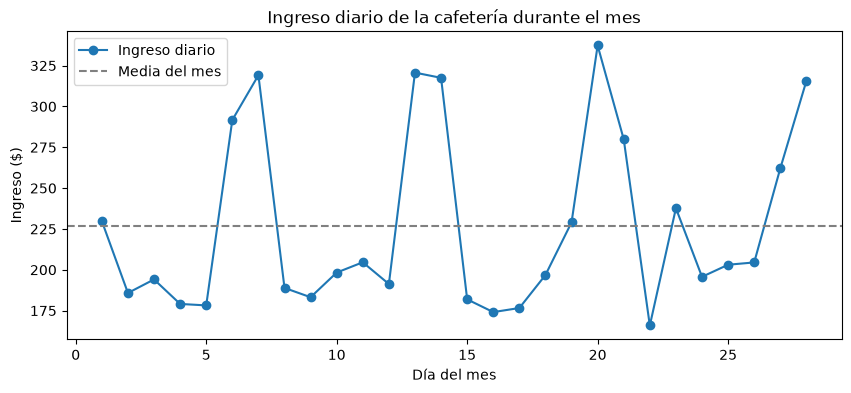

In [21]:
plt.figure(figsize=(10, 4))
plt.plot(dias, ingreso_diario, marker="o", label="Ingreso diario")
plt.axhline(ingreso_diario.mean(), color="gray", linestyle="--", label="Media del mes")
plt.title("Ingreso diario de la cafetería durante el mes")
plt.xlabel("Día del mes")
plt.ylabel("Ingreso ($)")
plt.legend()
plt.show()

**Ejercicio 16.** Quiero comparar cuánto dinero generó cada producto en el mes.

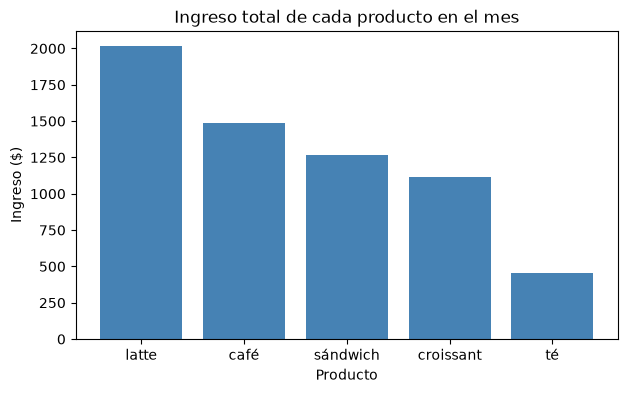

In [22]:
orden = ingreso_producto.argsort()[::-1]   # de mayor a menor ingreso

plt.figure(figsize=(7, 4))
plt.bar(productos[orden], ingreso_producto[orden], color="steelblue")
plt.title("Ingreso total de cada producto en el mes")
plt.xlabel("Producto")
plt.ylabel("Ingreso ($)")
plt.show()

**Ejercicio 17.** Quiero ver en un mismo gráfico las unidades vendidas cada día de los 5 productos, una línea por producto.

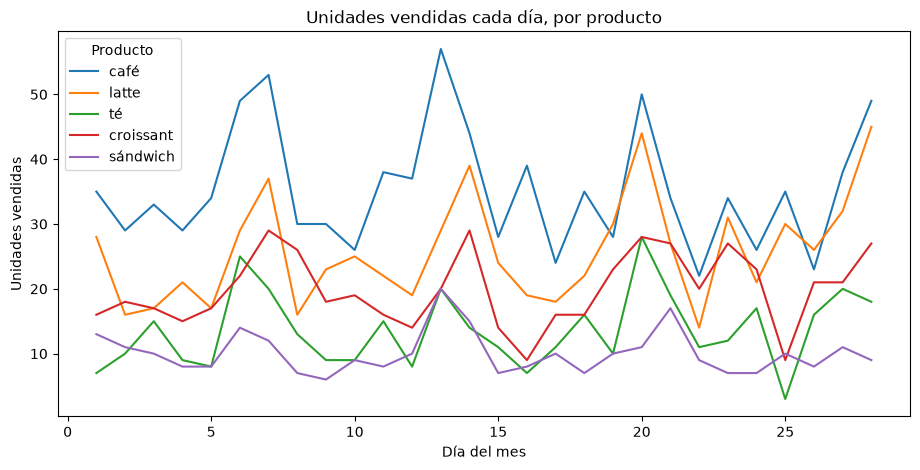

In [23]:
plt.figure(figsize=(11, 5))
for i, producto in enumerate(productos):
    plt.plot(dias, ventas[:, i], label=producto)
plt.title("Unidades vendidas cada día, por producto")
plt.xlabel("Día del mes")
plt.ylabel("Unidades vendidas")
plt.legend(title="Producto")
plt.show()

**Ejercicio 18.** Quiero ver la matriz de ventas (días × productos) como un mapa de calor.

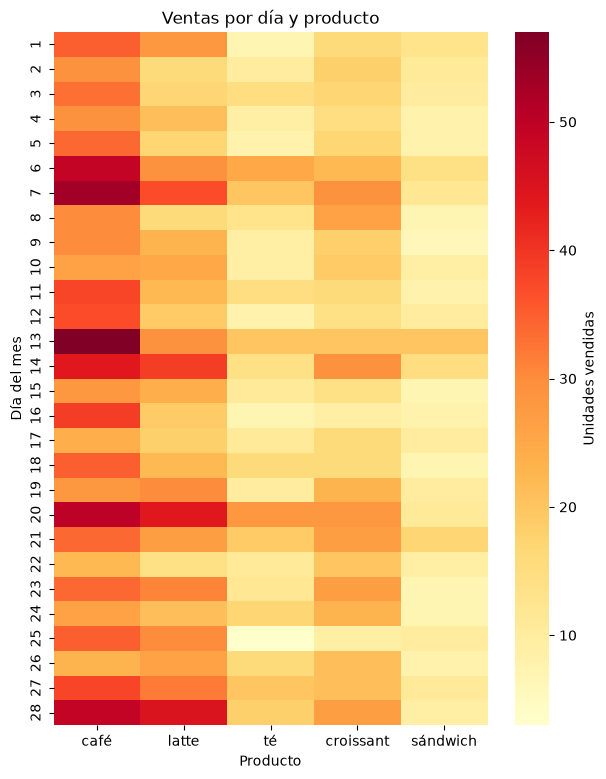

In [24]:
plt.figure(figsize=(7, 9))
sns.heatmap(ventas, xticklabels=productos, yticklabels=dias, cmap="YlOrRd", cbar_kws={"label": "Unidades vendidas"})
plt.title("Ventas por día y producto")
plt.xlabel("Producto")
plt.ylabel("Día del mes")
plt.show()

### Con los datos de las propinas 💵

Usa el DataFrame `propinas` tal como quedó al final de la Parte 2.

**Ejercicio 19.** Quiero ver el histograma del importe de la cuenta.

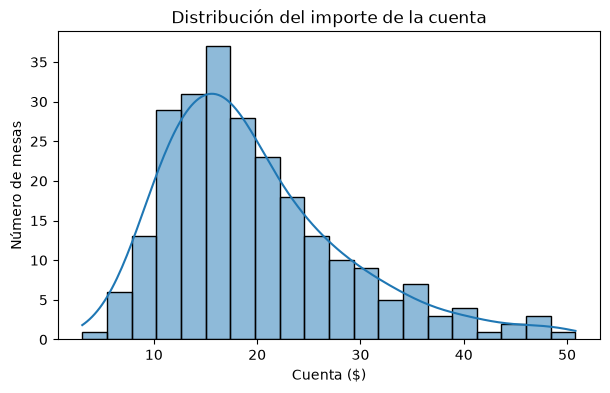

In [25]:
plt.figure(figsize=(7, 4))
sns.histplot(data=propinas, x="cuenta", bins=20, kde=True)
plt.title("Distribución del importe de la cuenta")
plt.xlabel("Cuenta ($)")
plt.ylabel("Número de mesas")
plt.show()

**Ejercicio 20.** Quiero visualizar la relación entre la cuenta y la propina.

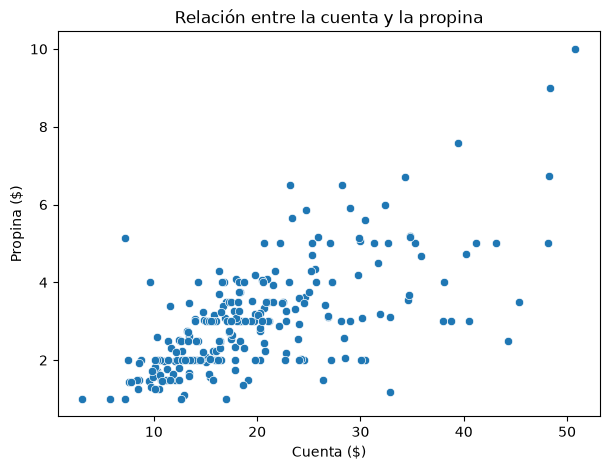

In [26]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=propinas, x="cuenta", y="propina")
plt.title("Relación entre la cuenta y la propina")
plt.xlabel("Cuenta ($)")
plt.ylabel("Propina ($)")
plt.show()

**Ejercicio 21.** Quiero ver esa misma relación, pero distinguiendo las comidas de las cenas.

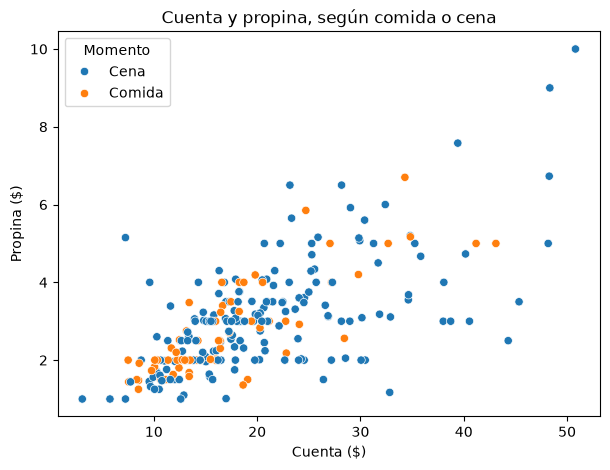

In [27]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=propinas, x="cuenta", y="propina", hue="momento")
plt.title("Cuenta y propina, según comida o cena")
plt.xlabel("Cuenta ($)")
plt.ylabel("Propina ($)")
plt.legend(title="Momento")
plt.show()

**Ejercicio 22.** Quiero ver si hay valores atípicos en el porcentaje de propina de cada día de la semana.

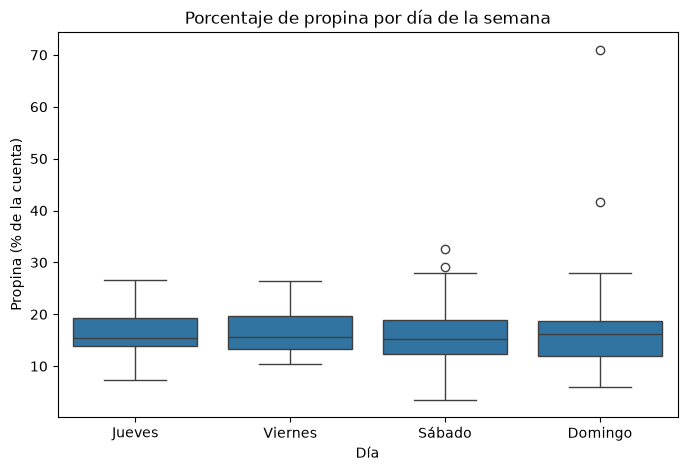

In [28]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=propinas, x="dia", y="pct_propina", order=["Jueves", "Viernes", "Sábado", "Domingo"])
plt.title("Porcentaje de propina por día de la semana")
plt.xlabel("Día")
plt.ylabel("Propina (% de la cuenta)")
plt.show()

**Ejercicio 23.** Quiero ver cuántas mesas se atendieron cada día.

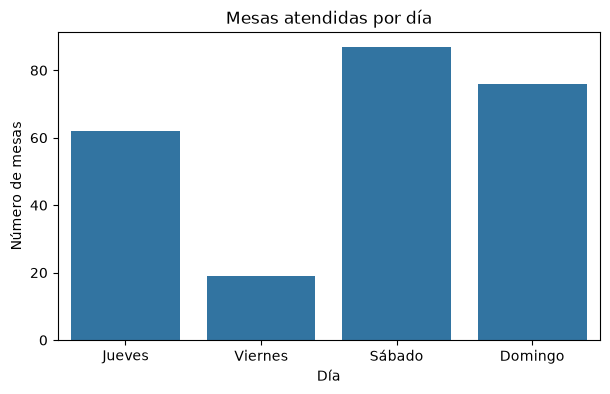

In [29]:
plt.figure(figsize=(7, 4))
sns.countplot(data=propinas, x="dia", order=["Jueves", "Viernes", "Sábado", "Domingo"])
plt.title("Mesas atendidas por día")
plt.xlabel("Día")
plt.ylabel("Número de mesas")
plt.show()

**Ejercicio 24.** Quiero comparar la propina media según el número de personas en la mesa, separando mesas de fumadores y de no fumadores.

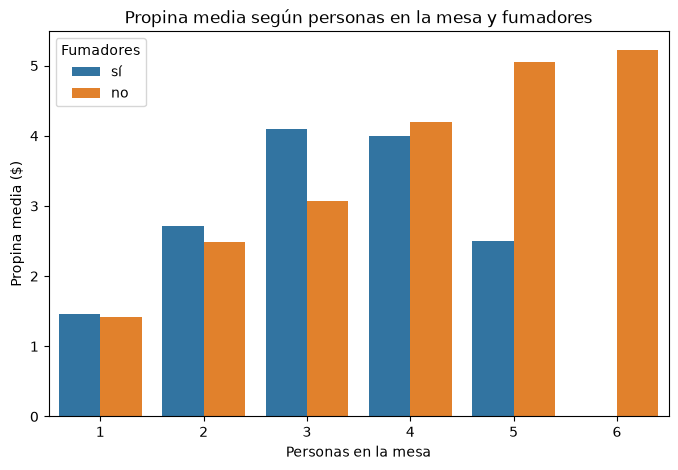

In [30]:
plt.figure(figsize=(8, 5))
sns.barplot(data=propinas, x="personas", y="propina", hue="fumador", errorbar=None)
plt.title("Propina media según personas en la mesa y fumadores")
plt.xlabel("Personas en la mesa")
plt.ylabel("Propina media ($)")
plt.legend(title="Fumadores")
plt.show()

### Con un dataset nuevo: los pingüinos 🐧

El archivo `data/penguins.csv` tiene medidas de 344 pingüinos de tres especies de la Antártida:

| Columna | Significado |
|---|---|
| `species` | especie: `Adelie`, `Chinstrap`, `Gentoo` |
| `island` | isla donde se registró |
| `bill_length_mm` | longitud del pico (mm) |
| `bill_depth_mm` | profundidad (altura) del pico (mm) |
| `flipper_length_mm` | longitud de la aleta (mm) |
| `body_mass_g` | peso (g) |
| `sex` | `Male` / `Female` |

**Ejercicio 25.** Carga los datos en un DataFrame llamado `pinguinos`. Quiero ver el histograma del peso de los pingüinos.

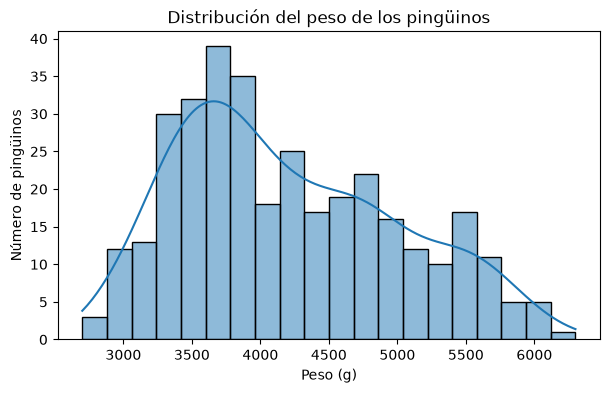

In [31]:
pinguinos = pd.read_csv(DATA_DIR / "penguins.csv")

plt.figure(figsize=(7, 4))
sns.histplot(data=pinguinos, x="body_mass_g", bins=20, kde=True)
plt.title("Distribución del peso de los pingüinos")
plt.xlabel("Peso (g)")
plt.ylabel("Número de pingüinos")
plt.show()

**Ejercicio 26.** Quiero ver si la distribución del peso cambia según la especie.

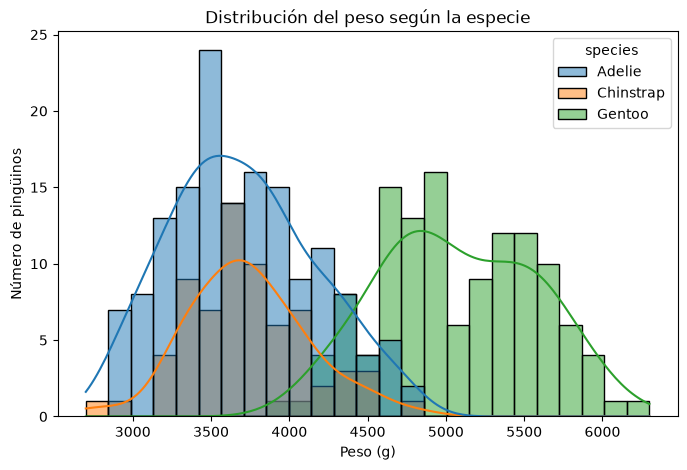

In [32]:
plt.figure(figsize=(8, 5))
sns.histplot(data=pinguinos, x="body_mass_g", hue="species", bins=25, kde=True)
plt.title("Distribución del peso según la especie")
plt.xlabel("Peso (g)")
plt.ylabel("Número de pingüinos")
plt.show()

**Ejercicio 27.** Quiero ver si hay valores atípicos en la longitud de la aleta de cada especie.

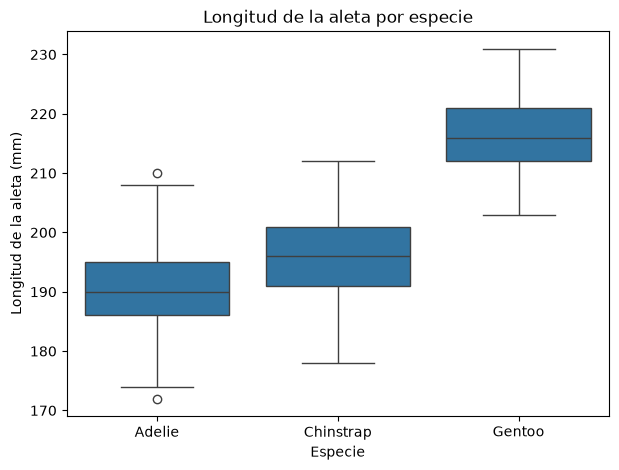

In [33]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=pinguinos, x="species", y="flipper_length_mm")
plt.title("Longitud de la aleta por especie")
plt.xlabel("Especie")
plt.ylabel("Longitud de la aleta (mm)")
plt.show()

**Ejercicio 28.** Quiero visualizar la relación entre la longitud y la profundidad del pico, distinguiendo las especies.

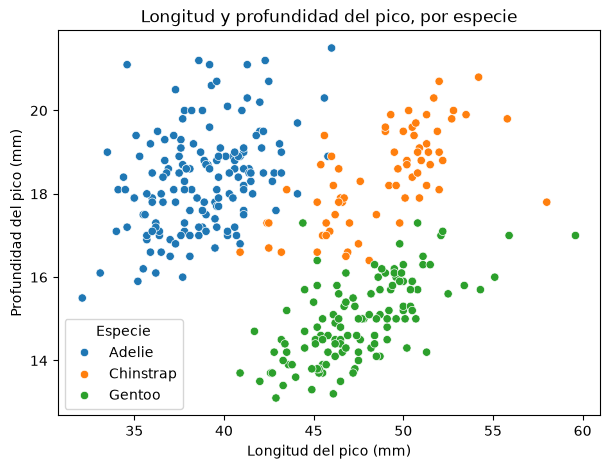

In [34]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=pinguinos, x="bill_length_mm", y="bill_depth_mm", hue="species")
plt.title("Longitud y profundidad del pico, por especie")
plt.xlabel("Longitud del pico (mm)")
plt.ylabel("Profundidad del pico (mm)")
plt.legend(title="Especie")
plt.show()

**Ejercicio 29.** Quiero ver en una sola figura el histograma de las cuatro medidas numéricas, cada una en su propio gráfico.

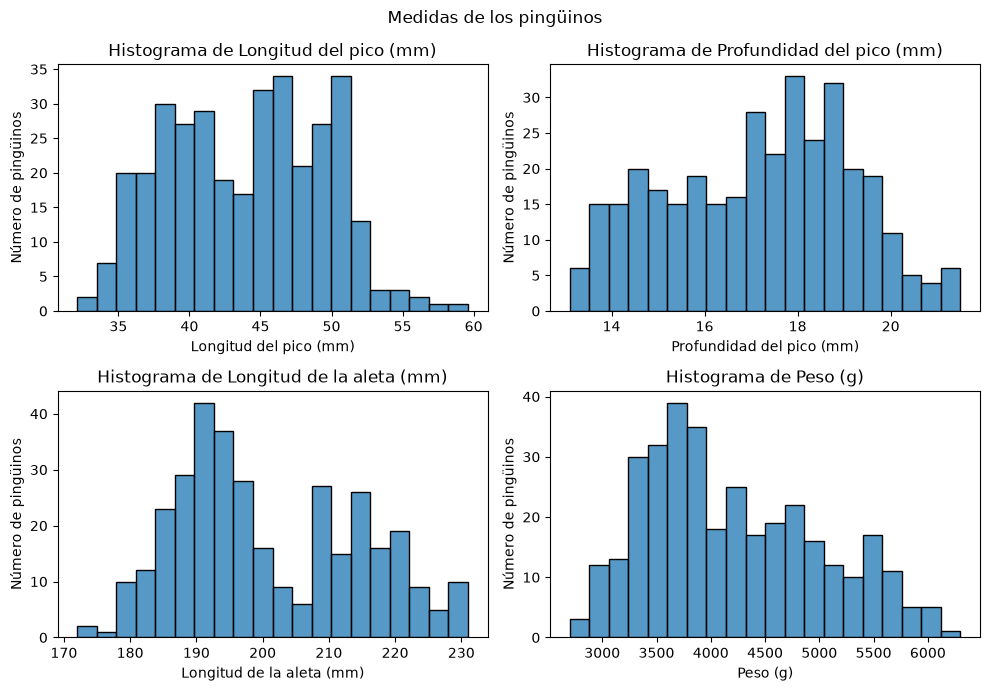

In [35]:
medidas = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
etiquetas_medidas = ["Longitud del pico (mm)", "Profundidad del pico (mm)", "Longitud de la aleta (mm)", "Peso (g)"]

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, col, etiqueta in zip(axes.ravel(), medidas, etiquetas_medidas):
    sns.histplot(data=pinguinos, x=col, bins=20, ax=ax)
    ax.set_title(f"Histograma de {etiqueta}")
    ax.set_xlabel(etiqueta)
    ax.set_ylabel("Número de pingüinos")
fig.suptitle("Medidas de los pingüinos")
plt.tight_layout()
plt.show()

**Ejercicio 30.** Quiero ver qué medidas numéricas están más relacionadas entre sí.

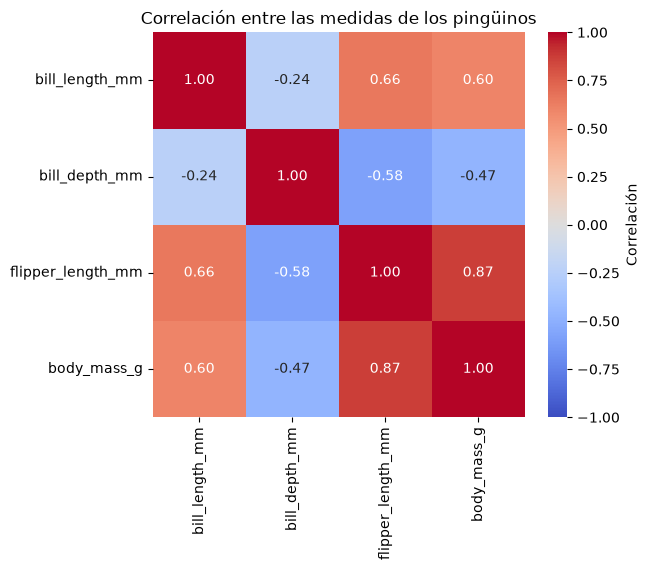

In [36]:
correlaciones = pinguinos[medidas].corr()

plt.figure(figsize=(6, 5))
sns.heatmap(correlaciones, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            cbar_kws={"label": "Correlación"})
plt.title("Correlación entre las medidas de los pingüinos")
plt.show()

**Ejercicio 31.** Quiero comparar el peso medio de cada especie, separando machos y hembras.

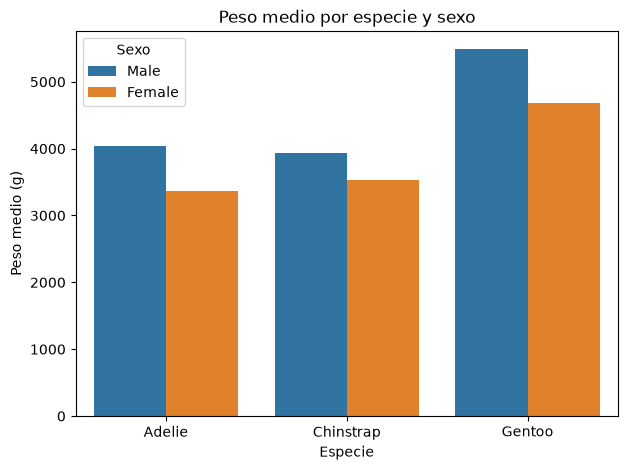

In [37]:
plt.figure(figsize=(7, 5))
sns.barplot(data=pinguinos, x="species", y="body_mass_g", hue="sex", errorbar=None)
plt.title("Peso medio por especie y sexo")
plt.xlabel("Especie")
plt.ylabel("Peso medio (g)")
plt.legend(title="Sexo")
plt.show()